# Tugas 2 — Visualisasi Data Deret Waktu

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Baca data mentah (path relatif), semua kolom sebagai teks dulu
raw = pd.read_csv("../datasets/203012420009_operasional.csv", dtype=str)
raw.shape

(5647, 6)

## Bagian A — Pemeriksaan awal

### A0. Struktur dan tipe data

In [3]:
raw.head(10)

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
0,2025-10-17,Tasikmalaya,226,17100700.0,18,2.0
1,2024-09-30,Bekasi,269,21995700.0,14,3.0
2,2025-02-05,Bekasi,310,25070900.0,17,5.0
3,2025-03-06,Garut,312,24489600.0,12,2.0
4,2024-02-22,Cirebon,178,14449500.0,13,3.0
5,2024-06-01,Tasikmalaya,248,19284800.0,9,3.0
6,2024-04-06,Cirebon,254,20341000.0,12,2.0
7,2025-01-08,Cimahi,179,13627500.0,7,NaN
8,2025-07-01,Depok,384,31789200.0,15,4.0
9,2024-10-03,Sumedang,102,8244600.0,5,2.0


In [4]:
# Konversi tipe; nilai yang gagal dikonversi menjadi NaN
df = raw.copy()
df["tanggal"] = pd.to_datetime(df["tanggal"], errors="coerce")
NUM = ["transaksi", "omzet", "keluhan", "staf_aktif"]
for k in NUM:
    df[k] = pd.to_numeric(df[k], errors="coerce")

# Nilai yang gagal dikonversi (di luar yang memang kosong)
gagal = {k: int((df[k].isna() & raw[k].notna()).sum()) for k in ["tanggal"] + NUM}
gagal

{'tanggal': 0, 'transaksi': 0, 'omzet': 0, 'keluhan': 0, 'staf_aktif': 0}

In [5]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5647 entries, 0 to 5646
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   tanggal     5647 non-null   datetime64[ns]
 1   cabang      5647 non-null   object        
 2   transaksi   5647 non-null   int64         
 3   omzet       5647 non-null   float64       
 4   keluhan     5647 non-null   int64         
 5   staf_aktif  5580 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 264.8+ KB


,count,mean,min,25%,50%,75%,max,std
tanggal,5647,2024-12-21 05:12:37.995396096,2024-01-01 00:00:00,2024-06-27 00:00:00,2024-12-21 00:00:00,2025-06-17 00:00:00,2025-12-11 00:00:00,NaN
transaksi,5647.0,366.875863,0.0,179.0,269.0,373.0,20617.0,1025.782485
omzet,5647.0,22196056.578714,0.0,13834000.0,20865300.0,29000750.0,80904300.0,10586247.750114
keluhan,5647.0,15.44289,0.0,9.0,14.0,20.0,71.0,8.633332
staf_aktif,5580.0,3.273297,2.0,2.0,3.0,4.0,7.0,1.232166


In [6]:
# Nilai kosong per kolom
hilang = df.isna().sum()
pd.DataFrame({"jumlah": hilang, "persen": (hilang / len(df) * 100).round(2)})

,jumlah,persen
tanggal,0,0.00
cabang,0,0.00
transaksi,0,0.00
omzet,0,0.00
keluhan,0,0.00
staf_aktif,67,1.19


In [7]:
# Kolom hitungan yang seharusnya bilangan bulat
{k: int((df[k].dropna() % 1 != 0).sum()) for k in NUM}

{'transaksi': 0, 'omzet': 0, 'keluhan': 0, 'staf_aktif': 0}

In [8]:
# Daftar cabang dan jumlah baris
df["cabang"].value_counts()

cabang
Cimahi         712
Sumedang       709
Bekasi         707
Garut          707
Bandung        705
Depok          704
Tasikmalaya    703
Cirebon        700
Name: count, dtype: int64

### A1. Rentang tanggal dan kelengkapan

In [9]:
# Rentang tanggal per cabang
rentang = df.groupby("cabang")["tanggal"].agg(awal="min", akhir="max", baris="size", tanggal_unik="nunique")
rentang["hari_kalender"] = (rentang["akhir"] - rentang["awal"]).dt.days + 1
rentang

,awal,akhir,baris,tanggal_unik,hari_kalender
cabang,,,,,
Bandung,2024-01-01,2025-12-11,705,701,711
Bekasi,2024-01-01,2025-12-11,707,703,711
Cimahi,2024-01-01,2025-12-11,712,708,711
Cirebon,2024-01-01,2025-12-11,700,698,711
Depok,2024-01-02,2025-12-11,704,699,710
Garut,2024-01-01,2025-12-11,707,704,711
Sumedang,2024-01-01,2025-12-11,709,705,711
Tasikmalaya,2024-01-01,2025-12-11,703,701,711


In [10]:
# Grid lengkap tanggal x cabang untuk melihat tanggal yang tidak punya baris
semua_tgl = pd.date_range(df["tanggal"].min(), df["tanggal"].max(), freq="D")
grid = pd.MultiIndex.from_product([semua_tgl, sorted(df["cabang"].unique())], names=["tanggal", "cabang"])
ada = df.groupby(["tanggal", "cabang"]).size().reindex(grid, fill_value=0).rename("n_baris")

print("total pasangan tanggal-cabang:", len(grid))
ada.value_counts().sort_index()

total pasangan tanggal-cabang: 5688


n_baris
0      69
1    5591
2      28
Name: count, dtype: int64

In [11]:
# Tanggal tanpa baris, diringkas menjadi blok berurutan per cabang
kosong = ada[ada == 0].reset_index()[["tanggal", "cabang"]].sort_values(["cabang", "tanggal"])
kosong["blok"] = (kosong.groupby("cabang")["tanggal"].diff().dt.days != 1).cumsum()
blok_kosong = (kosong.groupby(["cabang", "blok"])["tanggal"]
               .agg(mulai="min", selesai="max", hari="size")
               .reset_index(drop=False).drop(columns="blok"))
blok_kosong

,cabang,mulai,selesai,hari
0,Bandung,2024-01-11,2024-01-11,1
1,Bandung,2024-04-18,2024-04-19,2
2,Bandung,2024-07-05,2024-07-05,1
3,Bandung,2024-11-28,2024-11-28,1
4,Bandung,2024-12-28,2024-12-28,1
...,...,...,...,...
62,Tasikmalaya,2025-05-20,2025-05-20,1
63,Tasikmalaya,2025-08-07,2025-08-07,1
64,Tasikmalaya,2025-09-02,2025-09-02,1
65,Tasikmalaya,2025-10-25,2025-10-25,1


In [12]:
# Jumlah baris per bulan per cabang
df.pivot_table(index=df["tanggal"].dt.to_period("M"), columns="cabang", values="transaksi", aggfunc="size")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,30,31,31,29,28,31,32,30
2024-02,29,29,28,28,30,29,29,29
2024-03,31,31,31,31,31,31,30,31
2024-04,28,30,30,29,29,30,30,31
2024-05,31,30,31,30,31,31,31,30
2024-06,31,30,30,30,27,28,30,30
2024-07,30,32,32,31,31,31,31,31
2024-08,31,30,30,31,33,29,31,30
2024-09,30,30,30,28,31,30,30,30


In [13]:
# Jumlah baris per tanggal pada 30 hari terakhir
df[df["tanggal"] > df["tanggal"].max() - pd.Timedelta(days=30)].groupby("tanggal").size()

tanggal
2025-11-12    8
2025-11-13    8
2025-11-14    8
2025-11-15    8
2025-11-16    8
2025-11-17    8
2025-11-18    8
2025-11-19    7
2025-11-20    8
2025-11-21    9
2025-11-22    8
2025-11-23    8
2025-11-24    8
2025-11-25    8
2025-11-26    7
2025-11-27    8
2025-11-28    8
2025-11-29    8
2025-11-30    8
2025-12-01    8
2025-12-02    8
2025-12-03    8
2025-12-04    8
2025-12-05    8
2025-12-06    8
2025-12-07    8
2025-12-08    8
2025-12-09    8
2025-12-10    7
2025-12-11    8
dtype: int64

### A2. Duplikat

In [14]:
# Baris yang identik seluruh kolom
print("duplikat persis:", raw.duplicated().sum())

# Satu cabang dan satu tanggal yang punya lebih dari satu baris
kunci = df.duplicated(["tanggal", "cabang"], keep=False)
print("baris dengan kunci ganda:", kunci.sum())
df[kunci].sort_values(["cabang", "tanggal"])

duplikat persis: 0
baris dengan kunci ganda: 56


,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
242,2024-06-09,Bandung,578,43279700.0,44,6.0
1291,2024-06-09,Bandung,535,40094600.0,44,6.0
1523,2024-10-12,Bandung,624,44744000.0,33,5.0
5630,2024-10-12,Bandung,544,43577200.0,33,5.0
635,2024-12-04,Bandung,357,21603200.0,22,4.0
931,2024-12-04,Bandung,345,25281000.0,22,4.0
335,2025-02-03,Bandung,357,25819000.0,16,5.0
1866,2025-02-03,Bandung,312,27714700.0,16,5.0
3188,2024-01-25,Bekasi,196,15224100.0,10,3.0
3729,2024-01-25,Bekasi,215,17203900.0,10,3.0


### A3. Nilai nol, negatif, dan ekstrem

In [15]:
# Jumlah nilai nol dan negatif per kolom per cabang
pd.concat({
    "nol": df[NUM].eq(0).groupby(df["cabang"]).sum(),
    "negatif": df[NUM].lt(0).groupby(df["cabang"]).sum(),
}, axis=1)

nol                            negatif                \
            transaksi omzet keluhan staf_aktif transaksi omzet keluhan   
cabang                                                                   
Bandung             4     4       4          0         0     0       0   
Bekasi              3     3       3          0         0     0       0   
Cimahi              5     5       5          0         0     0       0   
Cirebon             8     8       8          0         0     0       0   
Depok               3     3       3          0         0     0       0   
Garut               5     5       6          0         0     0       0   
Sumedang            2     2       3          0         0     0       0   
Tasikmalaya         3     3       3          0         0     0       0   

                        
            staf_aktif  
cabang                  
Bandung              0  
Bekasi               0  
Cimahi               0  
Cirebon              0  
Depok                0  
Garut                0  
Sumedang             0  
Tasikmalaya          0

In [16]:
# Baris yang memiliki nilai nol di salah satu kolom
df[df[NUM].eq(0).any(axis=1)].sort_values(["cabang", "tanggal"])

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
248,2024-09-04,Bandung,0,0.0,0,4.0
1821,2025-03-25,Bandung,0,0.0,0,5.0
271,2025-05-29,Bandung,0,0.0,0,5.0
3857,2025-08-24,Bandung,0,0.0,0,6.0
3150,2024-05-20,Bekasi,0,0.0,0,4.0
1042,2024-07-01,Bekasi,0,0.0,0,4.0
5018,2025-02-17,Bekasi,0,0.0,0,5.0
2037,2024-03-11,Cimahi,0,0.0,0,3.0
1999,2024-08-06,Cimahi,0,0.0,0,3.0
2919,2024-08-20,Cimahi,0,0.0,0,NaN


In [17]:
# Statistik transaksi per cabang
df.groupby("cabang")[NUM].describe(percentiles=[.01, .5, .99]).round(1)

transaksi                                                       \
                count    mean     std  min     1%    50%      99%      max   
cabang                                                                       
Bandung         705.0  1023.6  2623.3  0.0  236.2  440.0  15679.5  18766.0   
Bekasi          707.0   394.4   113.0  0.0  185.0  386.0    670.9    978.0   
Cimahi          712.0   294.6   816.7  0.0  129.1  249.0    431.4  20617.0   
Cirebon         700.0   279.6   417.6  0.0    0.0  254.0    446.2   9666.0   
Depok           704.0   344.7    92.6  0.0  186.0  338.5    568.0    829.0   
Garut           707.0   265.2   134.6  0.0   85.1  248.0    561.8    840.0   
Sumedang        709.0   132.0    36.2  0.0   70.1  128.0    225.0    326.0   
Tasikmalaya     703.0   202.2   361.4  0.0  100.0  179.0    302.0   8640.0   

             omzet              ... keluhan       staf_aktif                 \
             count        mean  ...     99%   max      count mean  std  min   
cabang                          ...                                           
Bandung      705.0  34474886.0  ...    50.0  71.0      692.0  5.3  0.7  3.0   
Bekasi       707.0  30827195.8  ...    44.0  64.0      702.0  4.3  0.7  3.0   
Cimahi       712.0  19913019.2  ...    26.0  34.0      708.0  3.0  0.6  2.0   
Cirebon      700.0  20119360.7  ...    26.0  35.0      694.0  2.9  0.6  2.0   
Depok        704.0  26908682.1  ...    35.0  41.0      692.0  4.0  0.7  2.0   
Garut        707.0  20758280.3  ...    20.0  24.0      697.0  2.2  0.4  2.0   
Sumedang     709.0  10269983.6  ...    17.0  22.0      703.0  2.1  0.2  2.0   
Tasikmalaya  703.0  14336632.3  ...    20.0  25.0      692.0  2.3  0.5  2.0   

                                 
              1%  50%  99%  max  
cabang                           
Bandung      4.0  5.0  7.0  7.0  
Bekasi       3.0  4.0  6.0  6.0  
Cimahi       2.0  3.0  4.0  5.0  
Cirebon      2.0  3.0  4.0  5.0  
Depok        3.0  4.0  5.0  6.0  
Garut        2.0  2.0  3.0  4.0  
Sumedang     2.0  2.0  3.0  3.0  
Tasikmalaya  2.0  2.0  4.0  4.0  

[8 rows x 32 columns]

In [18]:
# Nilai tertinggi tiap kolom dan rasionya terhadap median cabangnya
def teratas(kolom, n=15):
    med = df.groupby("cabang")[kolom].transform("median")
    out = df.assign(rasio_median=(df[kolom] / med).round(2))
    return out.nlargest(n, kolom)[["tanggal", "cabang", kolom, "rasio_median"]]

teratas("transaksi")

,tanggal,cabang,transaksi,rasio_median
1155,2025-08-23,Cimahi,20617,82.80
3868,2024-08-17,Bandung,18766,42.65
5526,2024-08-16,Bandung,18210,41.39
4774,2024-08-15,Bandung,17733,40.30
5153,2024-08-14,Bandung,17336,39.40
2442,2024-08-13,Bandung,16970,38.57
3642,2024-08-12,Bandung,16616,37.76
449,2024-08-11,Bandung,16257,36.95
3618,2024-08-10,Bandung,15701,35.68
3116,2024-08-09,Bandung,15164,34.46


In [19]:
teratas("omzet")

,tanggal,cabang,omzet,rasio_median
2812,2025-06-06,Bandung,80904300.0,2.42
668,2025-06-06,Bekasi,78209500.0,2.60
251,2025-06-06,Garut,69762400.0,3.66
1180,2025-06-06,Depok,65096500.0,2.49
5344,2025-06-28,Bandung,64051600.0,1.92
1703,2025-07-26,Bandung,62336100.0,1.87
1944,2025-05-03,Bandung,60854600.0,1.82
37,2025-04-26,Bandung,60421400.0,1.81
3269,2025-08-16,Bandung,60187700.0,1.80
1606,2025-06-06,Cirebon,59768000.0,3.04


In [20]:
teratas("keluhan")

,tanggal,cabang,keluhan,rasio_median
2812,2025-06-06,Bandung,71,2.73
668,2025-06-06,Bekasi,64,2.78
1488,2024-06-06,Bandung,54,2.08
959,2025-07-19,Bandung,51,1.96
1703,2025-07-26,Bandung,51,1.96
1758,2025-07-19,Bekasi,51,2.22
2853,2024-12-12,Bandung,51,1.96
2529,2024-06-15,Bandung,50,1.92
3382,2025-04-26,Bekasi,50,2.17
4332,2025-09-07,Bandung,50,1.92


### A4. Besaran turunan per cabang

In [21]:
# Omzet per transaksi dan keluhan per 1000 transaksi
df["omzet_per_trx"] = df["omzet"] / df["transaksi"]
df["keluhan_per_1000"] = df["keluhan"] / df["transaksi"] * 1000
df.groupby("cabang")[["omzet_per_trx", "keluhan_per_1000"]].describe(percentiles=[.01, .5, .99]).round(1)

omzet_per_trx                                               \
                    count     mean      std      min       1%      50%   
cabang                                                                   
Bandung             701.0  73493.3  17854.6   1506.3   2096.7  77582.9   
Bekasi              704.0  78127.7   3951.2  66959.1  69538.4  78085.4   
Cimahi              707.0  77738.7   5673.0   1408.6  67277.0  77980.3   
Cirebon             692.0  77647.0   5612.4   1437.5  68051.8  77902.0   
Depok               701.0  78016.9   3947.1  65797.5  68866.2  77944.2   
Garut               702.0  78117.6   3699.9  68150.6  69923.0  78001.7   
Sumedang            707.0  77845.7   3983.5  66803.1  68786.3  77890.9   
Tasikmalaya         700.0  77757.6   5574.4   2073.0  68496.2  78052.4   

                              keluhan_per_1000                                \
                 99%      max            count  mean   std   min    1%   50%   
cabang                                                                         
Bandung      87206.6  90249.9            701.0  58.1  18.6   0.9   1.5  60.0   
Bekasi       87117.3  91188.0            704.0  59.8  13.2  24.5  32.8  58.9   
Cimahi       87043.1  93370.8            707.0  53.4  16.1   1.0  18.2  53.0   
Cirebon      86315.9  89406.1            692.0  52.0  15.2   1.2  19.4  51.4   
Depok        87503.5  96814.7            701.0  55.0  13.7  17.8  27.1  53.5   
Garut        86633.0  90158.0            702.0  43.9  23.3   0.0   9.3  37.5   
Sumedang     86710.6  97112.1            707.0  58.0  22.4   0.0  11.5  56.2   
Tasikmalaya  86793.5  92285.2            700.0  56.8  18.6   1.0  12.8  56.2   

                           
               99%    max  
cabang                     
Bandung       89.9  121.2  
Bekasi        92.9  103.6  
Cimahi        96.0  115.4  
Cirebon       89.8  104.2  
Depok         88.8  102.2  
Garut        106.4  168.5  
Sumedang     111.1  151.5  
Tasikmalaya  105.3  143.8

In [22]:
# Median bulanan per cabang
def median_bulanan(kolom):
    return df.pivot_table(index=df["tanggal"].dt.to_period("M"), columns="cabang", values=kolom, aggfunc="median").round(1)

median_bulanan("transaksi")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,279.5,224.0,162.0,155.0,213.5,101.0,86.5,122.5
2024-02,304.0,243.0,172.5,174.0,231.0,122.0,89.0,132.0
2024-03,346.0,282.0,189.0,195.0,261.0,130.0,100.5,148.0
2024-04,361.0,293.5,203.5,195.0,265.0,138.5,117.5,151.0
2024-05,381.0,331.0,237.0,215.0,294.0,147.0,118.0,162.0
2024-06,435.0,364.0,234.5,253.0,336.0,160.5,125.0,178.5
2024-07,5044.0,334.0,229.0,225.0,293.0,156.0,124.0,166.0
2024-08,12145.0,330.5,236.5,224.0,304.0,160.0,122.0,168.5
2024-09,379.0,339.0,216.0,218.0,299.0,151.5,110.5,159.5


In [23]:
median_bulanan("omzet_per_trx")

cabang,Bandung,Bekasi,Cimahi,Cirebon,Depok,Garut,Sumedang,Tasikmalaya
tanggal,,,,,,,,
2024-01,77530.8,77073.0,78183.3,77558.8,77719.4,77351.0,78102.4,76514.2
2024-02,77180.8,78754.1,79575.2,78866.9,77507.7,79508.5,78084.5,78778.1
2024-03,77653.2,78002.0,79068.0,77559.9,77833.5,78006.6,77717.3,78926.1
2024-04,77707.0,79156.3,77534.3,78217.3,79209.9,77980.6,78251.5,77427.9
2024-05,79769.3,77107.5,78577.5,77051.9,77408.5,77593.2,78418.9,77610.7
2024-06,76307.6,77978.4,76640.7,78535.2,78195.7,78071.7,77768.8,78076.4
2024-07,6021.1,75997.8,78783.1,77298.4,76919.3,78522.2,77762.5,78328.8
2024-08,3036.0,77260.2,78325.7,76989.8,76114.3,77163.9,77963.3,77578.0
2024-09,78328.6,78175.5,78558.5,77294.6,78213.6,76910.0,76919.1,78543.4


### A5. Plot deret mentah per cabang

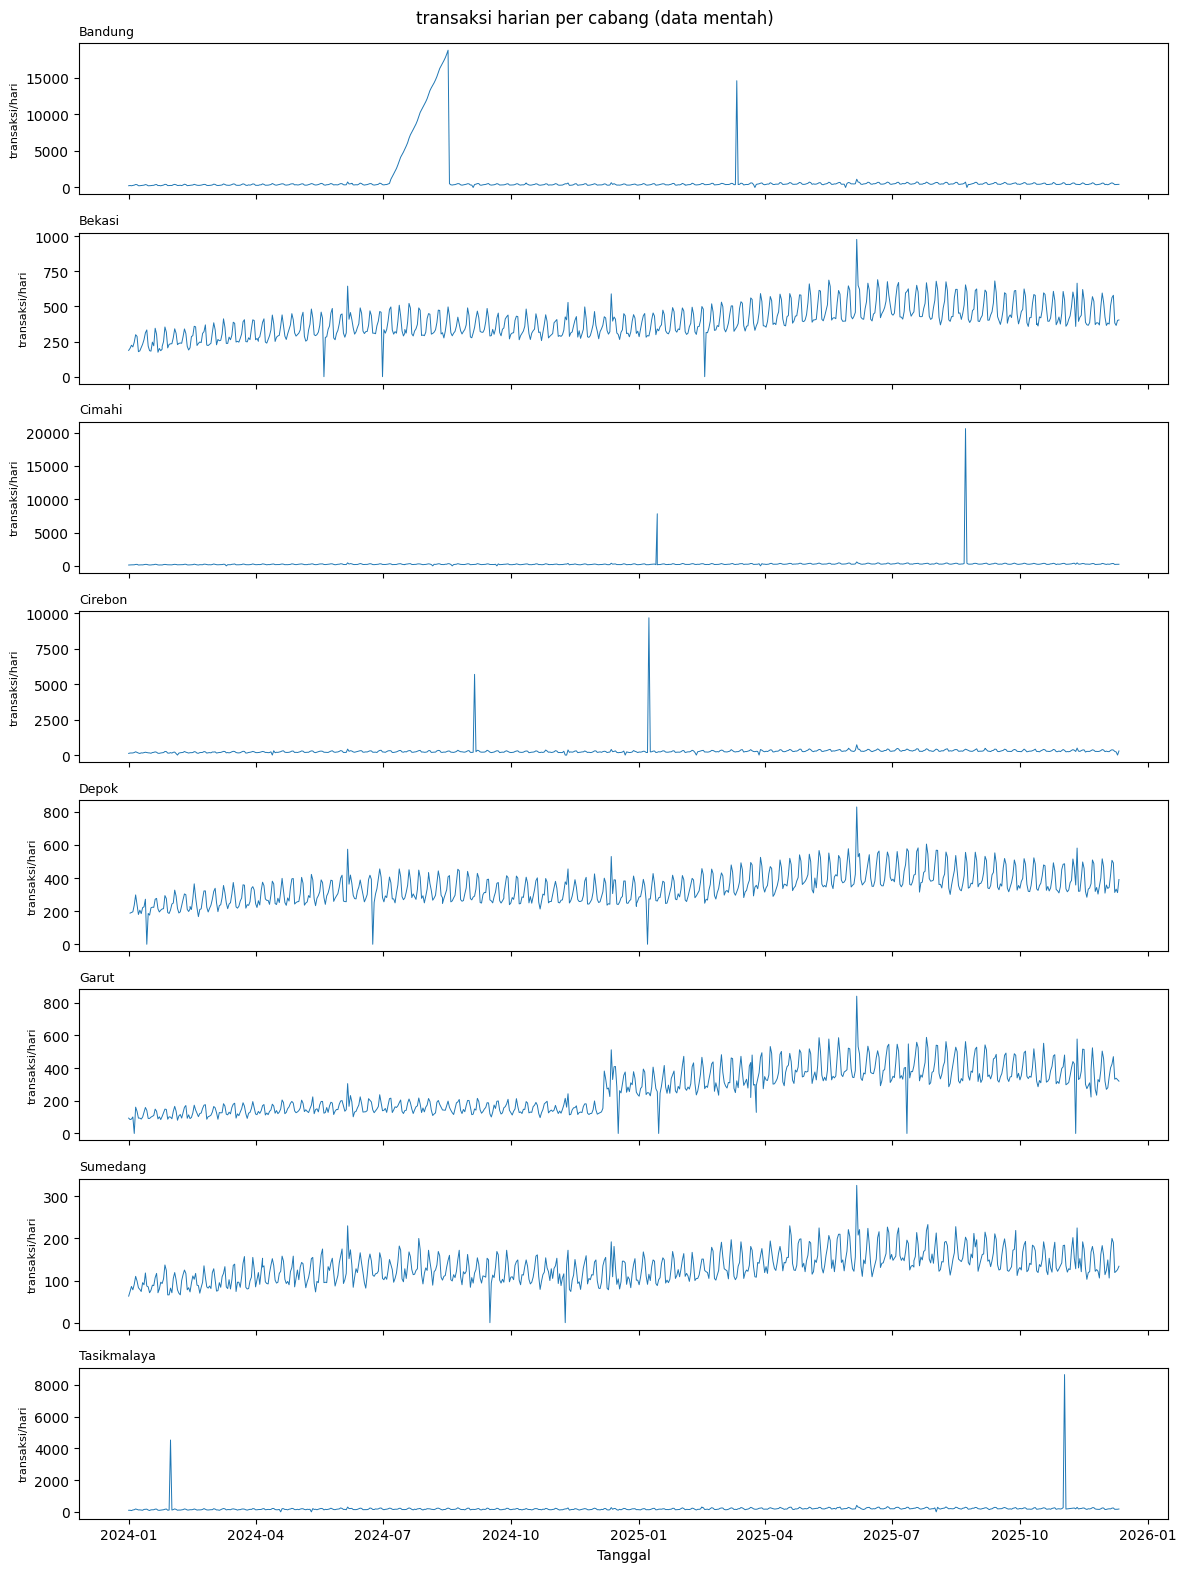

In [24]:
# Deret harian mentah satu kolom, satu panel per cabang
def plot_per_cabang(kolom, satuan, data=None):
    data = df if data is None else data
    cabang = sorted(data["cabang"].unique())
    fig, axes = plt.subplots(len(cabang), 1, figsize=(12, 2 * len(cabang)), sharex=True)
    for ax, c in zip(axes, cabang):
        s = data[data["cabang"] == c].sort_values("tanggal")
        ax.plot(s["tanggal"], s[kolom], lw=0.7)
        ax.set_title(c, loc="left", fontsize=9)
        ax.set_ylabel(satuan, fontsize=8)
    axes[-1].set_xlabel("Tanggal")
    fig.suptitle(f"{kolom} harian per cabang (data mentah)")
    fig.tight_layout()
    plt.show()

plot_per_cabang("transaksi", "transaksi/hari")

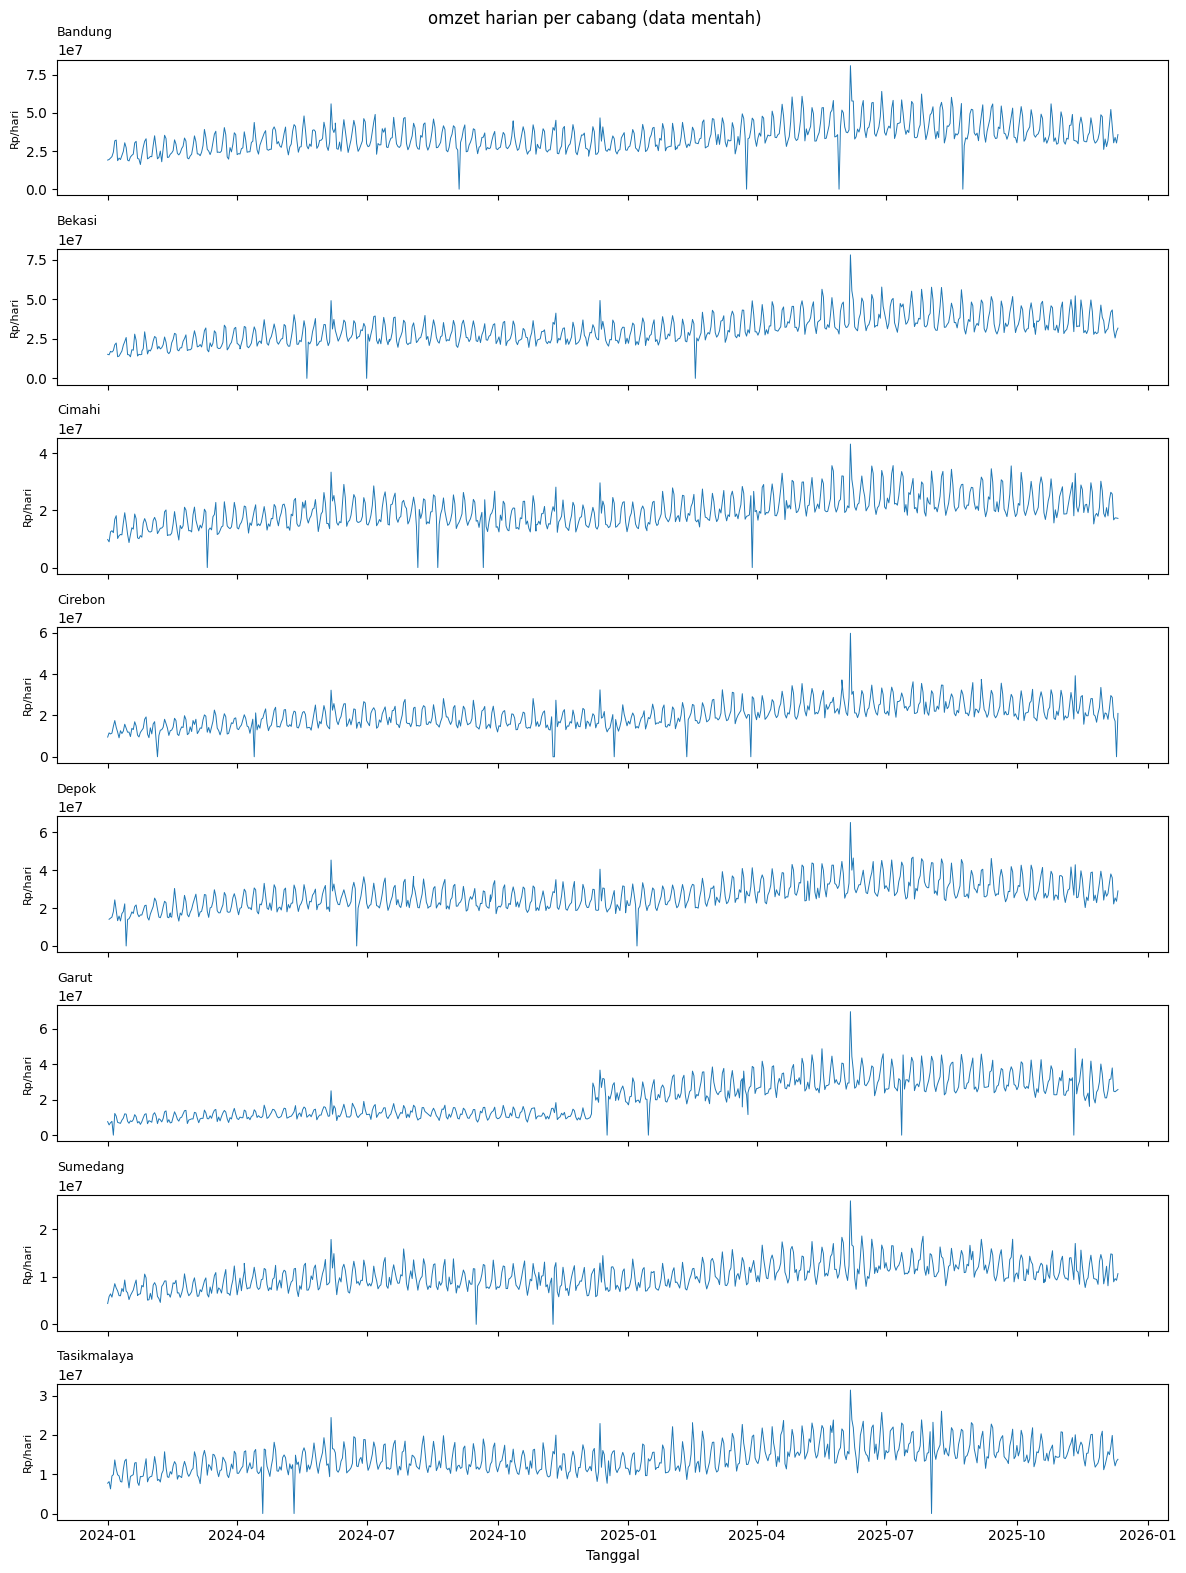

In [25]:
plot_per_cabang("omzet", "Rp/hari")

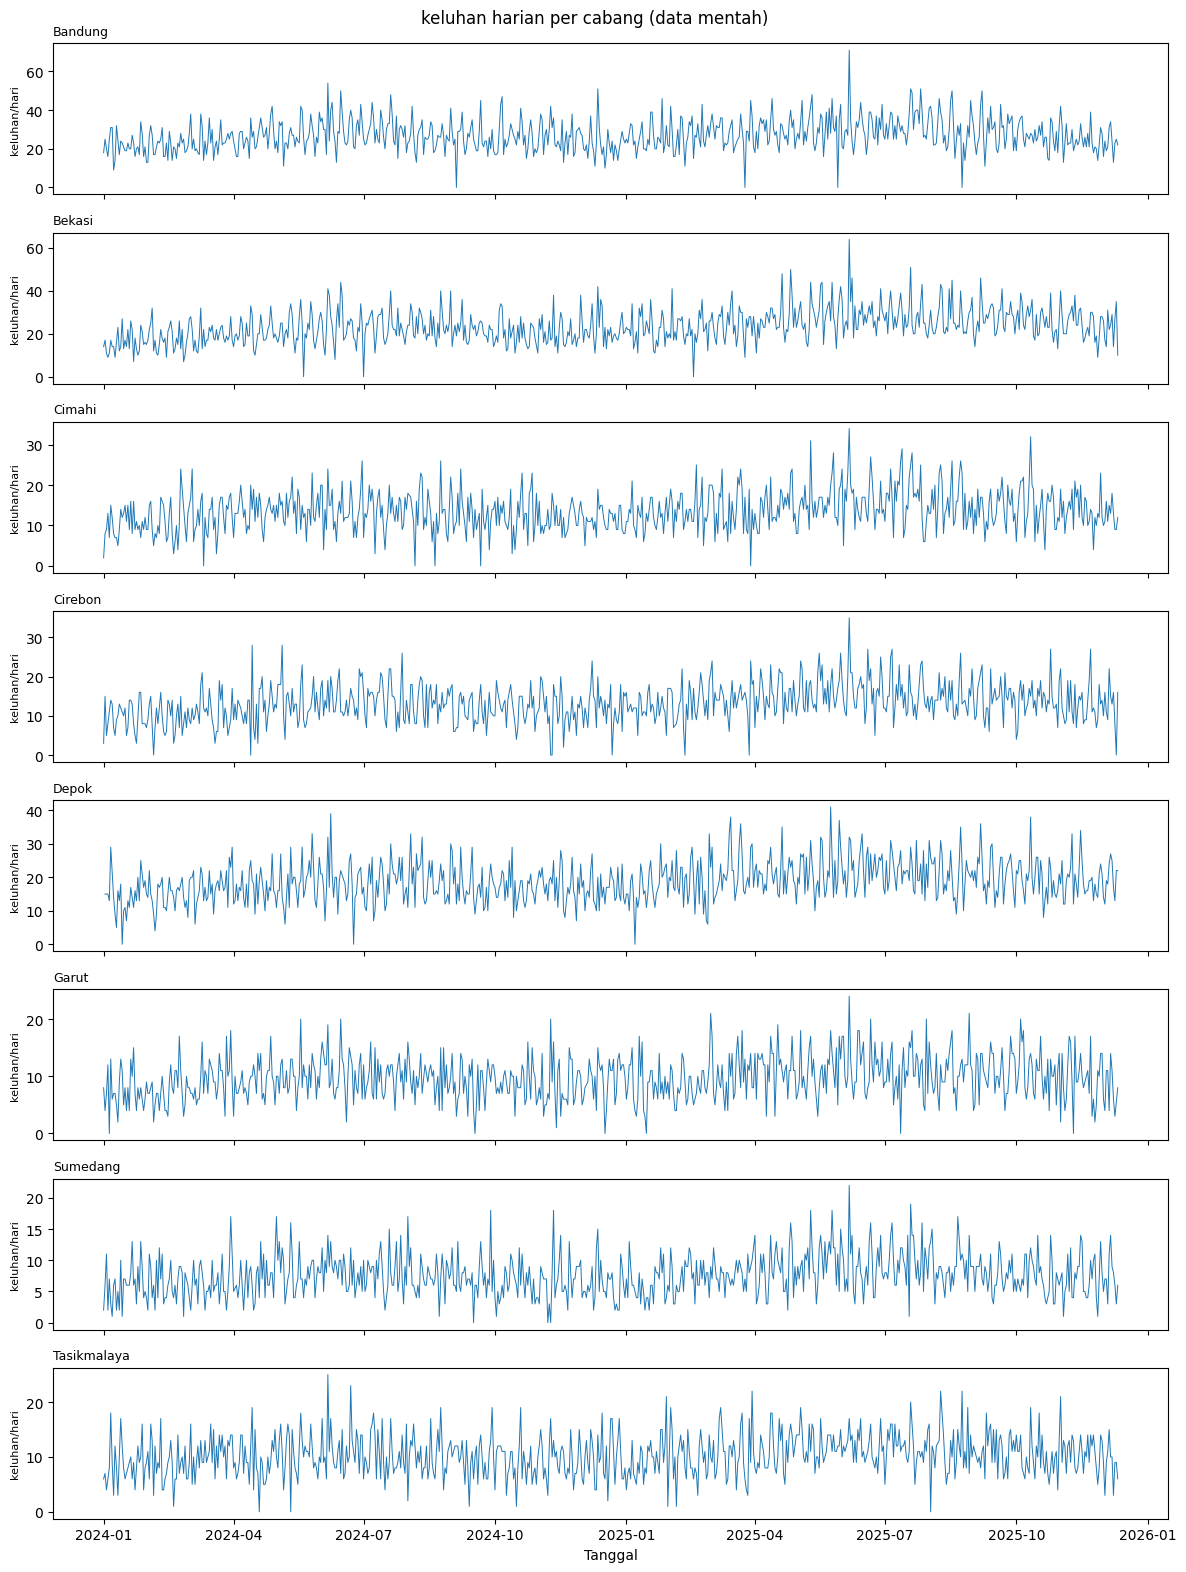

In [26]:
plot_per_cabang("keluhan", "keluhan/hari")

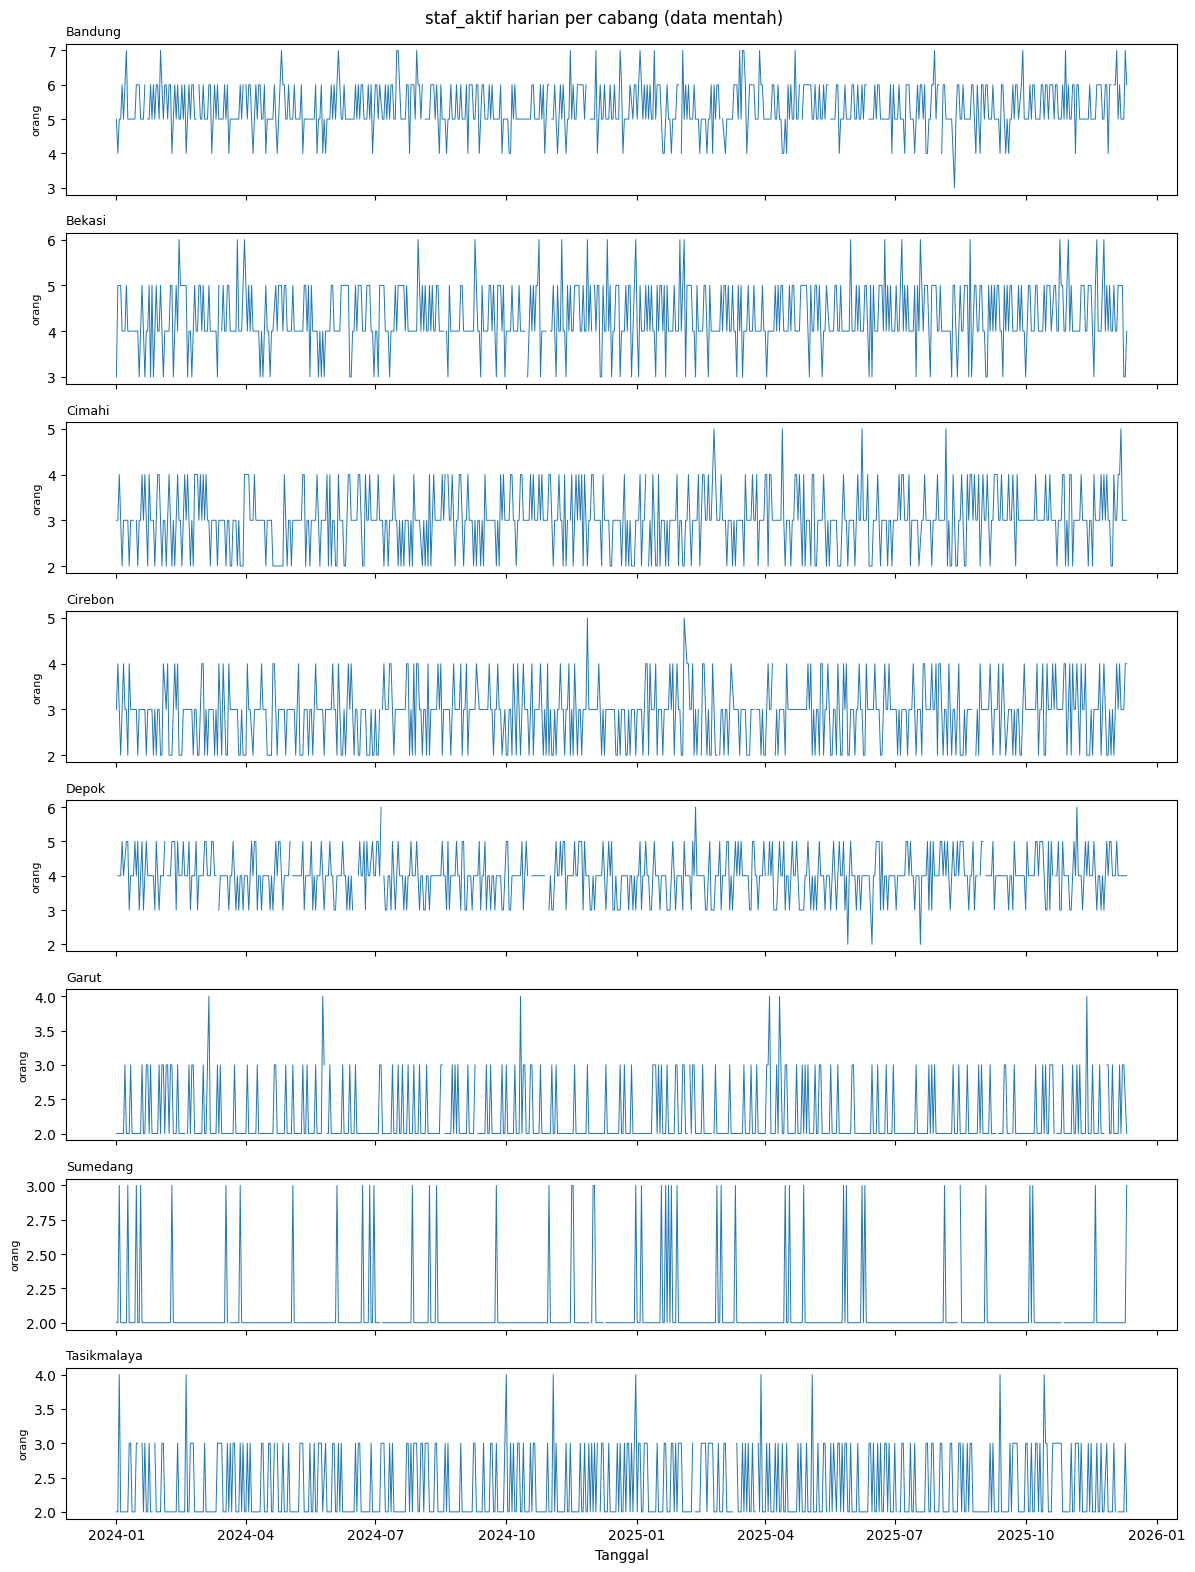

In [27]:
plot_per_cabang("staf_aktif", "orang")

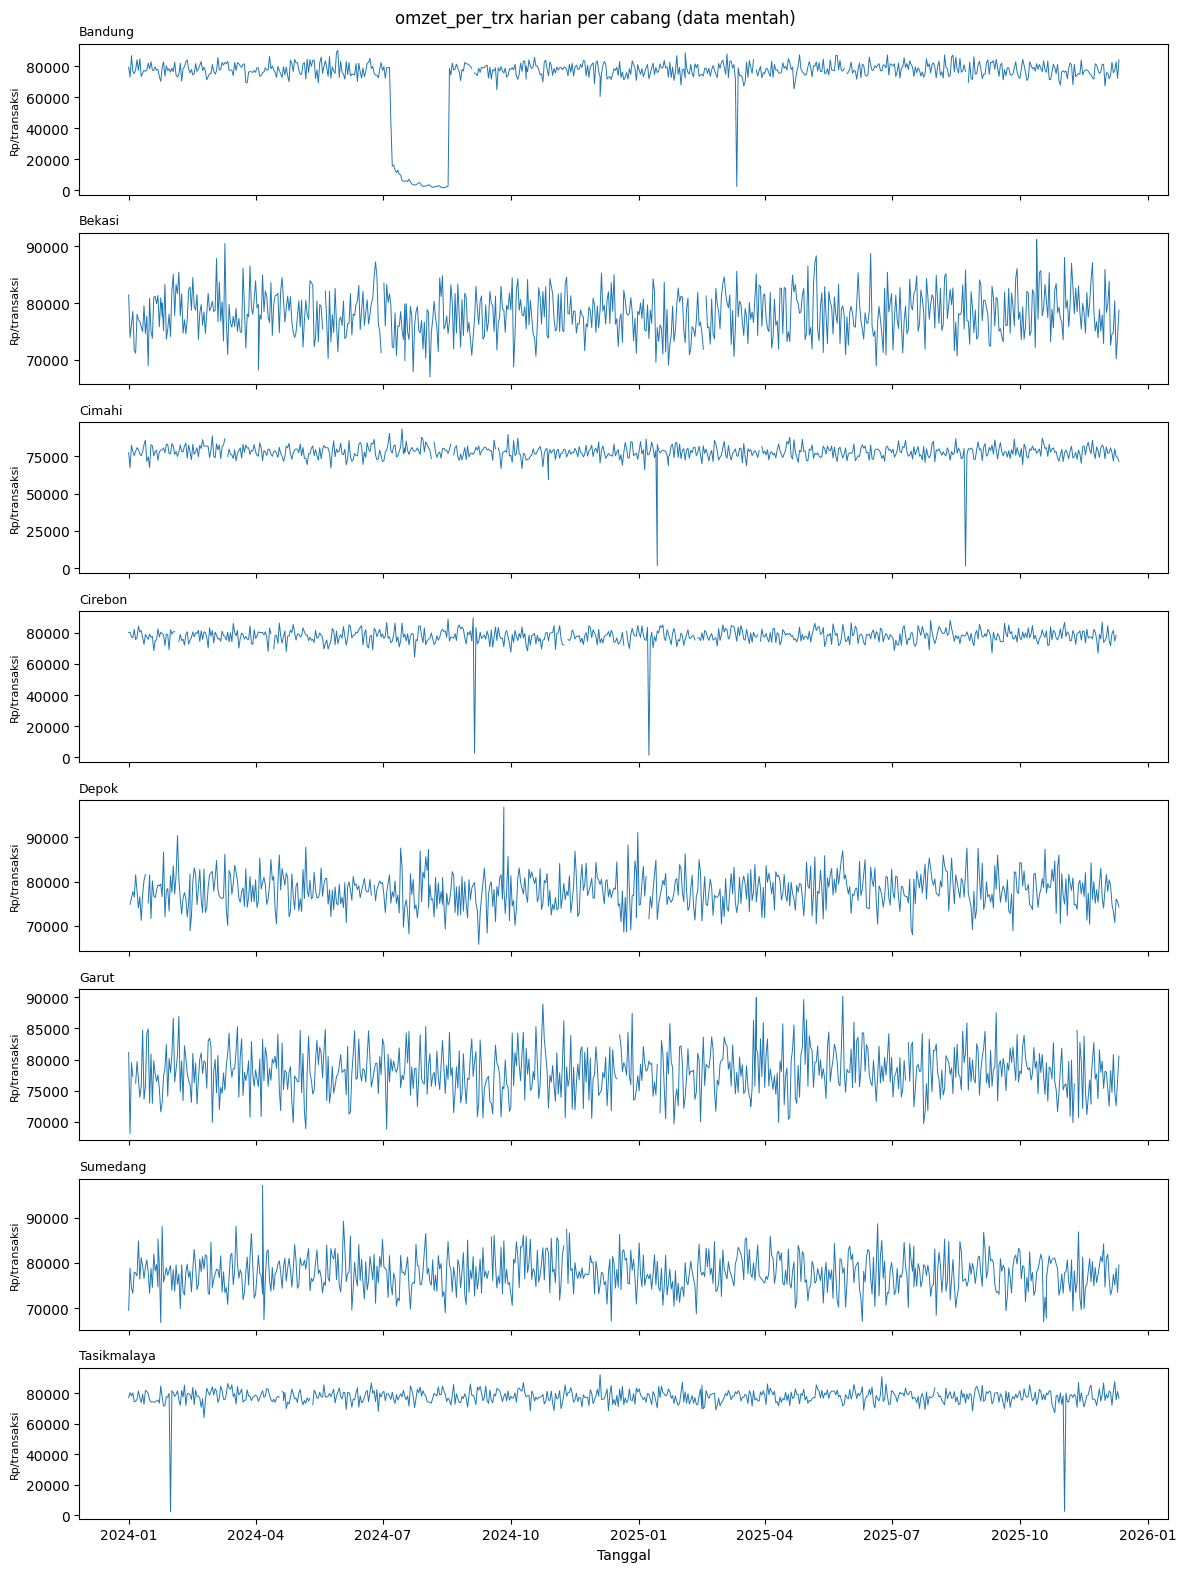

In [28]:
plot_per_cabang("omzet_per_trx", "Rp/transaksi")